# Biharmonic equation over the unit circle
Given the following system, defined over a disc $D$:
\begin{equation}
\begin{cases}
-\Delta u - \lambda u = |u|^{p-2}u&\text{ for } p>2, \lambda>0\\
u=0&\text{ on }\partial D
\end{cases}
\end{equation}
If we know that, for a given $p$, some non-trivial solutions satisfy certain topological conditions (eg. a fixed number of sign changes over the domain), then, is it possible to deform an initial guess function $\tilde{u}$, preserving those topological conditions, while minimizing the residuals of the equation ?

To do so, we propose to approximate the solution by $$\hat{u} = P \tilde{u}(F(x)),$$ with $P>0$, and $F(x)$ a diffeomorphism that satisfies $F(\partial D) = \partial d$. In the following, we fix $p = 3$, $\lambda=5$, and $D$ the unit circle.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np

torch.set_default_device(torch.device("mps" if torch.backends.mps.is_available() else "cpu"))
torch.set_default_dtype(torch.float32)
torch.manual_seed(0)

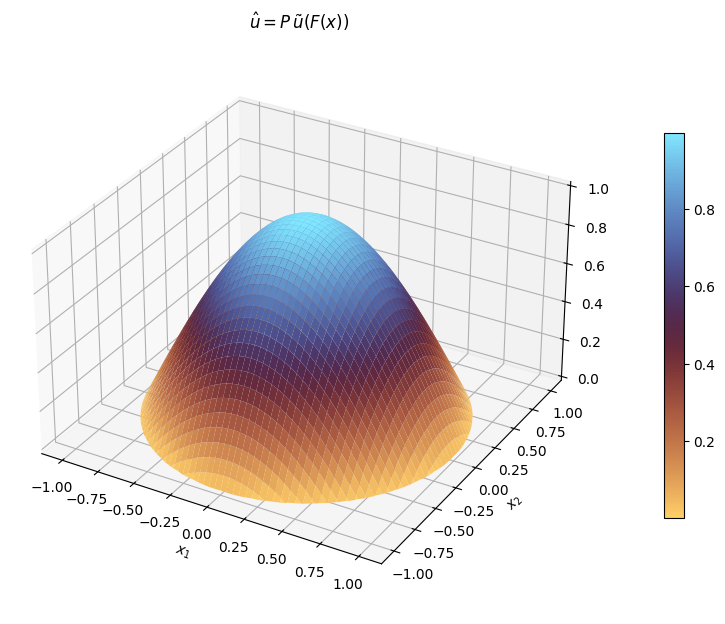

In [2]:
LAMBDA = 5 #4.7832 ##  5.7832 is the first eigenvalue = lambda + 1 if p=2
p = 3 # 2.01 ## p = 2 is the linear eigenvalue problem

def u_tilde(x1, x2):
    r2 = (x1**2 + x2**2)**0.5
    if type(x1) == np.ndarray:
        return np.cos(np.pi/2*r2)
    else:
        return torch.cos(torch.pi/2*r2)

freq = 2
def u_tilde2(x1, x2):
    r2 = (x1**2 + x2**2)**0.5
    if type(x1) == np.ndarray:
        res = np.sin(freq*x1) * (1 - r2)
    else:
        res = torch.sin(freq*x1) * (1 - r2)
    return res

x = np.linspace(-1, 1, 1000)
X1, X2 = np.meshgrid(x, x)
mask = X1**2 + X2**2 > 1
U = np.ma.array(u_tilde(X1, X2), mask=mask)

fig = plt.figure(figsize=(8, 8))
ax0 = fig.add_subplot(1, 1, 1, projection="3d")
surf0 = ax0.plot_surface(X1, X2, U, cmap="managua", linewidth=0, antialiased=True)
ax0.set_title(r"$\hat u = P\,\tilde u(F(x))$")
ax0.set_xlabel("$x_1$")
ax0.set_ylabel("$x_2$")
ax0.set_box_aspect((1, 1, 0.6))
fig.colorbar(surf0, ax=ax0, shrink=0.5, pad=0.1)
plt.tight_layout()
plt.show()

In [3]:
class AdditiveCoupling(nn.Module):
    def __init__(self, flip, hidden=32):
        super().__init__()
        self.flip = flip
        self.mlp = nn.Sequential(
            nn.Linear(1, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1), nn.Tanh()
        )
        nn.init.zeros_(self.mlp[-2].weight)
        nn.init.zeros_(self.mlp[-2].bias)

    def forward(self, z, inverse=False):
        a, b = (z[:, 1:], z[:, :1]) if self.flip else (z[:, :1], z[:, 1:])
        t = self.mlp(a)
        b = 2*b - t if inverse else (b + t)/2
        return torch.cat([b, a], 1) if self.flip else torch.cat([a, b], 1)

class InvertibleNN(nn.Module):
    def __init__(self, n_layers=8, hidden=32):
        super().__init__()
        self.layers = nn.ModuleList(
            [AdditiveCoupling(flip=i % 2 == 1, hidden=hidden) for i in range(n_layers)]
        )

    def forward(self, x, inverse=False):
        z = x
        for l in (reversed(self.layers) if inverse else self.layers):
            z = l(z, inverse)
        d = (1 - (x[:, 0]**2 + x[:, 1]**2)**0.5).unsqueeze(-1)
        return nn.Tanh()(d) * z + x * (1-nn.Tanh()(d))
        # return torch.stack([z[:, 0]*torch.cos(2*torch.pi*z[:, 1]), z[:, 0]*torch.sin(2*torch.pi*z[:, 1])], axis=-1)

In [4]:
def grad(y, x):
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]

def laplacian(u, x):
    g = grad(u, x)
    return sum(grad(g[:, i], x)[:, i] for i in range(x.shape[1]))

In [5]:
def loss_fn(F, P, x):
    fx = F(x)
    v = u_tilde(fx[:, 0], fx[:, 1])
    px = P(x).squeeze()
    u_hat = px * v
    lap = laplacian(u_hat, x)
    loss = (-lap - LAMBDA * u_hat - u_hat.abs() ** (p - 2) * u_hat)**2
    return loss.mean()/(u_hat**2).mean(), px.max()

def sample_disc(n):
    r = torch.sqrt(torch.rand(n, requires_grad=True))
    th = 2*torch.pi*torch.rand(n, requires_grad=True)
    return torch.stack([r*torch.cos(th), r*torch.sin(th)], 1)

In [6]:
import math
class AmplitudeNN(nn.Module):
    def __init__(self, n_hidden=16, min_thresh=1e-1):
        super().__init__()
        self.min_thresh = min_thresh
        self.layers = nn.Sequential(
            nn.Linear(2, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, n_hidden), nn.Tanh(),
            nn.Linear(n_hidden, 1), nn.Sigmoid())
        nn.init.zeros_(self.layers[-2].weight)
        nn.init.constant_(self.layers[-2].bias, math.log((1 - min_thresh) / min_thresh),)
        
    def forward(self, x):
        return self.layers(x) + self.min_thresh

In [9]:
n_epochs_adam, n_epochs_lbfgs = 10, 10
n_points_adam, n_points_lbfgs = 10, 10

F = InvertibleNN()
P = AmplitudeNN()

opt = optim.Adam(list(F.parameters())+list(P.parameters()), lr=1e-2)

stats = {}
def closure():
    opt.zero_grad()
    x = sample_disc(n_points_adam)
    loss, px_max = loss_fn(F, P, x)
    loss.backward()
    stats["loss"], stats["px_max"] = loss.detach(), px_max.detach()
    return loss

for _ in (pbar := tqdm(range(n_epochs_adam))):
    opt.step(closure)
    pbar.set_description(f"Loss: {stats['loss'].item():.3e}, P: {stats['px_max'].item():.4e}")

torch.set_default_dtype(torch.float64)
torch.set_default_device("cpu")
F, P = F.cpu().double(), P.cpu().double()

x_lbfgs = sample_disc(n_points_lbfgs).detach()

def closure():
    opt.zero_grad()
    x = x_lbfgs.clone().requires_grad_(True)
    loss, px_max = loss_fn(F, P, x)
    loss.backward()
    stats["loss"], stats["px_max"] = loss.detach(), px_max.detach()
    return loss

opt = optim.LBFGS(list(F.parameters()) + list(P.parameters()), lr=1, max_iter=30, history_size=50, tolerance_grad=1e-9, tolerance_change=1e-12, line_search_fn="strong_wolfe")

for _ in (pbar := tqdm(range(n_epochs_lbfgs))):
    opt.step(closure)
    pbar.set_description(f"Loss: {stats['loss'].item():.3e}, P: {stats['px_max'].item():.4e}")

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

In [10]:
def u_hat(P, f, x):
    fx = F(x)
    return P(x).squeeze() * u_tilde(fx[:, 0], fx[:, 1])

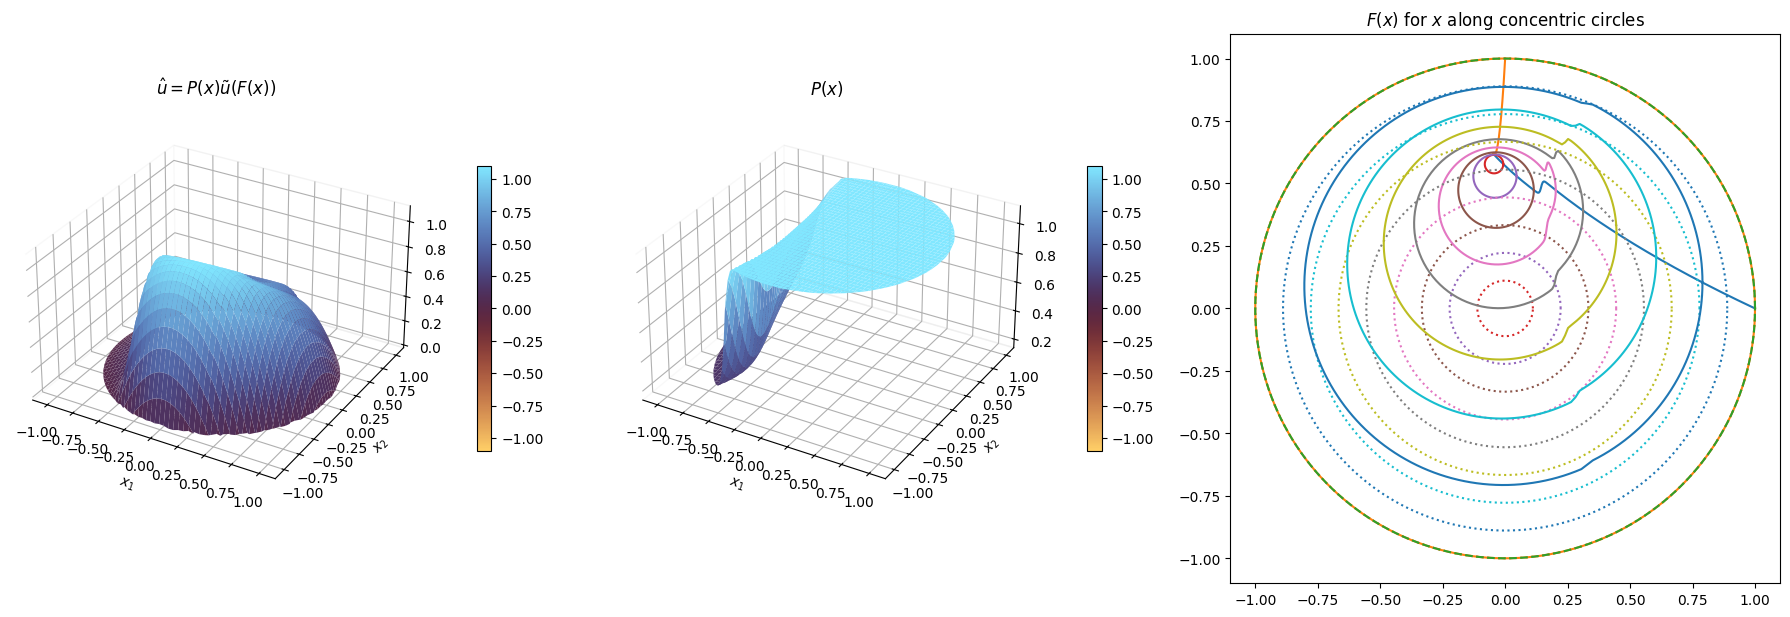

In [11]:
n = 512
xs = torch.linspace(-1, 1, n)
X1, X2 = torch.meshgrid(xs, xs, indexing="ij")
x = torch.stack([X1, X2], dim=-1).reshape(-1, 2)
with torch.no_grad():
    u = u_hat(P, F, x)
    px = P(x)

mask = (X1**2 + X2**2 > 1).cpu().numpy()
u_hat_masked = np.ma.array(u.reshape(n, n).cpu().numpy(), mask=mask)
px_masked = np.ma.array(px.reshape(n, n).cpu().numpy(), mask=mask)

X1_np, X2_np = X1.cpu().numpy(), X2.cpu().numpy()

u_s = u_hat_masked.filled(np.nan)
px_s = px_masked.filled(np.nan)

fig = plt.figure(figsize=(18, 6))

ax0 = fig.add_subplot(1, 3, 1, projection="3d")
surf0 = ax0.plot_surface(X1_np, X2_np, u_s, cmap="managua", linewidth=0, antialiased=True, vmin=-np.max(np.abs(u_hat_masked)), vmax=np.max(np.abs(u_hat_masked)))
ax0.set_title(r"$\hat u = P(x)\tilde u(F(x))$")
ax0.set_xlabel("$x_1$")
ax0.set_ylabel("$x_2$")
ax0.set_box_aspect((1, 1, 0.6))
ax0.xaxis.pane.fill = False
ax0.yaxis.pane.fill = False
ax0.zaxis.pane.fill = False
fig.colorbar(surf0, ax=ax0, shrink=0.5, pad=0.1)

ax1 = fig.add_subplot(1, 3, 2, projection="3d")
surf1 = ax1.plot_surface(X1_np, X2_np, px_s, cmap="managua", linewidth=0, antialiased=True, vmin=-np.max(np.abs(px_masked)), vmax=np.max(np.abs(px_masked)))
ax1.set_title(r"$P(x)$")
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_box_aspect((1, 1, 0.6))
ax1.xaxis.pane.fill = False
ax1.yaxis.pane.fill = False
ax1.zaxis.pane.fill = False
fig.colorbar(surf1, ax=ax1, shrink=0.5, pad=0.1)

rs = torch.linspace(0,1, 10)
thetas = torch.linspace(0, 2*torch.pi, 200)
xs, ys = torch.cos(thetas), torch.sin(thetas)
Xs = torch.stack([xs, ys], dim=-1).reshape(-1, 2)

Fts = [F(r*Xs) for r in rs]
ax2 = fig.add_subplot(1, 3, 3)
ts = torch.linspace(0,1, 200)
Fl0 = F(torch.stack([ts, torch.zeros_like(ts)], dim=-1).reshape(-1, 2)).cpu().detach()
Fl1 = F(torch.stack([torch.zeros_like(ts),ts], dim=-1).reshape(-1, 2)).cpu().detach()
ax2.plot(Fl0[:,0],Fl0[:,1])
ax2.plot(Fl1[:,0],Fl1[:,1])

for i in range(len(rs)):
    xt, yt = Fts[i][:, 0].cpu().detach(), Fts[i][:, 1].cpu().detach()
    line, = ax2.plot(xt, yt)
    ax2.plot(rs.cpu()[i] * xs.cpu(), rs.cpu()[i] * ys.cpu(), linestyle='dotted', color=line.get_color())

ax2.plot(xs.cpu(),ys.cpu(), linestyle='dashed')
ax2.set_aspect("equal")
ax2.set_title("$F(x)$ for $x$ along concentric circles")
plt.tight_layout()
plt.show()

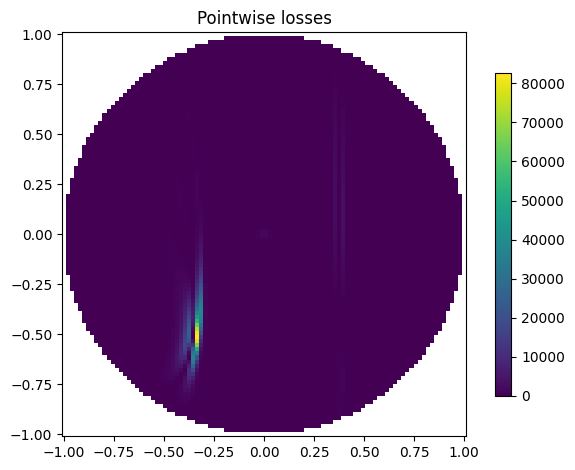

In [12]:
xs = torch.linspace(-1, 1, 100, requires_grad=True)
X1, X2 = torch.meshgrid(xs, xs, indexing="ij")
x = torch.stack([X1, X2], dim=-1).reshape(-1, 2)

px = P(x)
fx = F(x)
ufx = u_tilde(fx[:, 0], fx[:, 1])

ux = px.squeeze() * ufx
lap = laplacian(ux, x)
loss = (-lap - LAMBDA * ux - ux.abs() ** (p - 2) * ux)**2

mask = (X1**2 + X2**2 > 1).cpu().detach().numpy()
loss_masked = np.ma.array(loss.detach().reshape(100, 100).cpu().numpy(), mask=mask)

fig, ax = plt.subplots(1,1)

im2 = ax.pcolormesh(X1.detach().cpu(), X2.detach().cpu(), loss_masked)
ax.set_title(r"Pointwise losses")
ax.set_aspect("equal")
plt.colorbar(im2, ax=ax, shrink=0.8)


plt.tight_layout()
plt.show()